In [4]:
import pandas as pd
import numpy as np
import sys

sys.path.append("../src")

import clean
import features

data_folder = "../data/cleaned/"

names = ["orders", "order_items", "customers", "restaurants", "menu",
         "delivery_partners", "payments", "customer_feedback",
         "promotions", "cities", "traffic", "weather"]

tables = {}
clean_tables = {}

for n in names:
    tables[n] = pd.read_csv(data_folder + n + ".csv")
    clean_tables[n] = getattr(clean, "clean_" + n)(tables[n])

abt = clean.build_abt(clean_tables)
abt = features.build_features(abt)

print("ABT shape:", abt.shape)

ABT shape: (20475, 68)


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print(abt['OrderStatus'].value_counts())
print(abt['FinalAmount'].describe())

OrderStatus
Delivered             11390
Cancelled              4569
Food Not Delivered     2362
Delivered Late         2154
Name: count, dtype: int64
count    20475.000000
mean       391.715756
std        163.390136
min         33.000000
25%        273.000000
50%        382.900000
75%        502.600000
max       1011.200000
Name: FinalAmount, dtype: float64


In [6]:
revenue_orders = abt[abt['OrderStatus'].isin(['Delivered', 'Delivered Late'])]

print(revenue_orders.shape)
print("Total revenue:", revenue_orders['FinalAmount'].sum())

(13544, 68)
Total revenue: 5308590.4


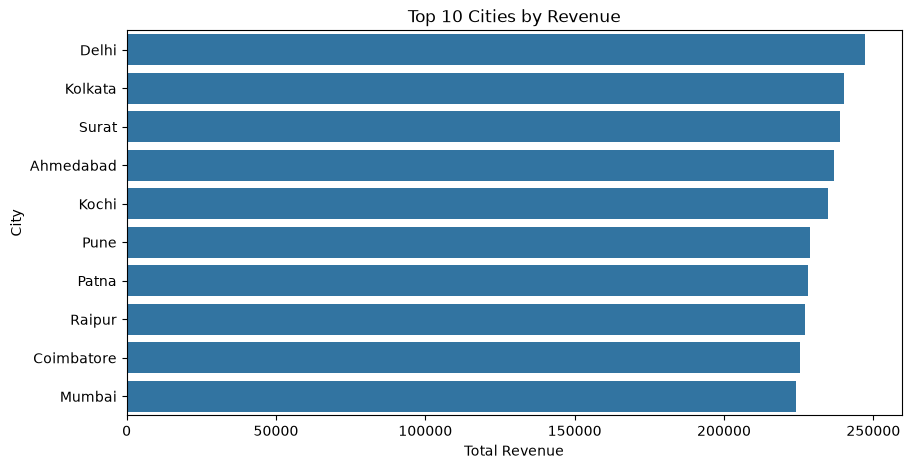

In [7]:
city_revenue = revenue_orders.groupby('RestaurantCity')['FinalAmount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=city_revenue.values, y=city_revenue.index)
plt.title('Top 10 Cities by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('City')
plt.show()

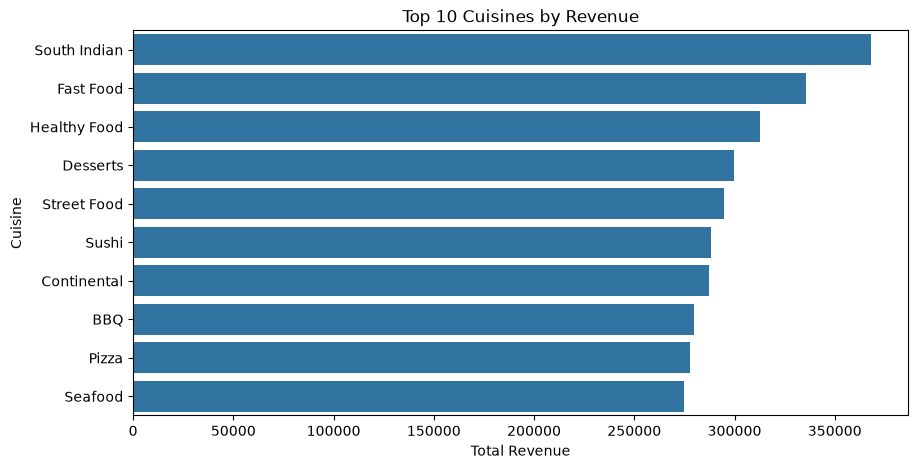

In [8]:
cuisine_revenue = revenue_orders.groupby('Cuisine')['FinalAmount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=cuisine_revenue.values, y=cuisine_revenue.index)
plt.title('Top 10 Cuisines by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Cuisine')
plt.show()

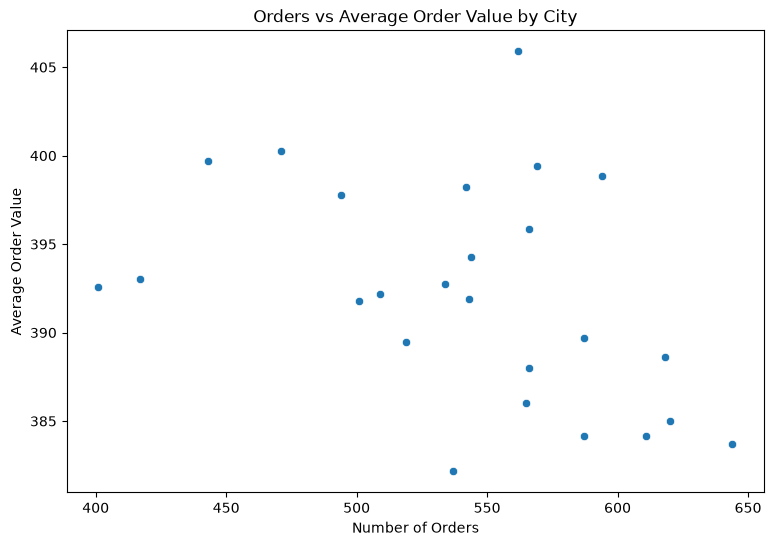

                Orders    Revenue  AvgOrderValue
RestaurantCity                                  
Guwahati           537  205214.25     382.149441
Delhi              644  247113.85     383.717158
Kochi              611  234734.30     384.180524
                Orders    Revenue  AvgOrderValue
RestaurantCity                                  
Vadodara           443  177070.75     399.708239
Nashik             471  188515.55     400.245329
Patna              562  228107.75     405.885676


In [9]:
city_stats = revenue_orders.groupby('RestaurantCity').agg(
    Orders=('OrderID', 'count'),
    Revenue=('FinalAmount', 'sum')
)
city_stats['AvgOrderValue'] = city_stats['Revenue'] / city_stats['Orders']

plt.figure(figsize=(9, 6))
sns.scatterplot(data=city_stats, x='Orders', y='AvgOrderValue')
plt.title('Orders vs Average Order Value by City')
plt.xlabel('Number of Orders')
plt.ylabel('Average Order Value')
plt.show()

print(city_stats.sort_values('AvgOrderValue').head(3))
print(city_stats.sort_values('AvgOrderValue').tail(3))

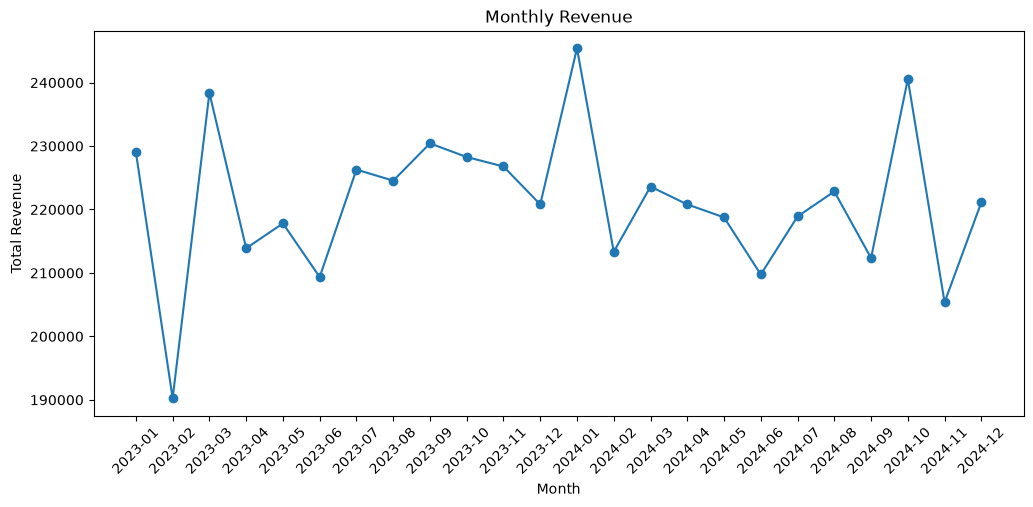

YearMonth
2023-01    229025.90
2023-02    190235.25
2023-03    238373.80
2023-04    213887.20
2023-05    217810.00
2023-06    209353.25
2023-07    226287.50
2023-08    224542.50
2023-09    230418.30
2023-10    228269.80
2023-11    226778.55
2023-12    220801.40
2024-01    245398.60
2024-02    213334.60
2024-03    223610.05
2024-04    220802.65
2024-05    218755.75
2024-06    209756.75
2024-07    218901.60
2024-08    222840.40
2024-09    212351.55
2024-10    240547.60
2024-11    205372.50
2024-12    221134.90
Name: FinalAmount, dtype: float64


In [10]:
monthly = revenue_orders.copy()
monthly['YearMonth'] = pd.to_datetime(monthly['OrderDate']).dt.to_period('M').astype(str)

monthly_revenue = monthly.groupby('YearMonth')['FinalAmount'].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker='o')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

print(monthly_revenue)

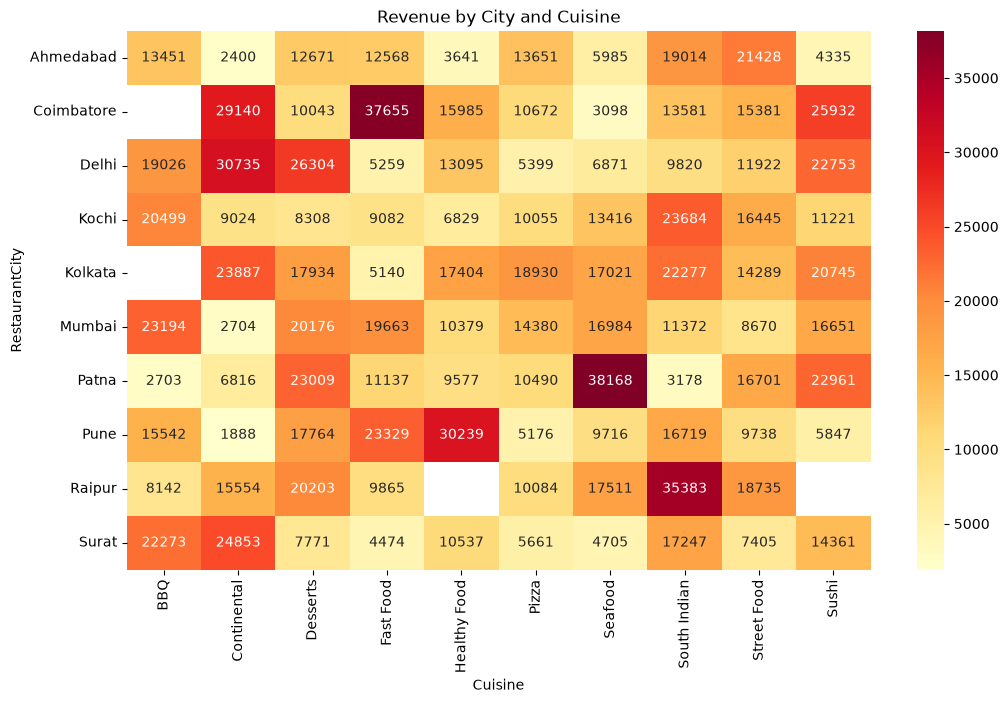

In [11]:
heat_data = revenue_orders[
    revenue_orders['RestaurantCity'].isin(city_revenue.index) &
    revenue_orders['Cuisine'].isin(cuisine_revenue.index)
]

pivot = heat_data.pivot_table(index='RestaurantCity', columns='Cuisine',
                              values='FinalAmount', aggfunc='sum')

plt.figure(figsize=(12, 7))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Revenue by City and Cuisine')
plt.show()

In [12]:
print(abt['DeliveryTimeMinutes'].isna().sum(), "missing values")
print()
print(abt.groupby('OrderStatus')['DeliveryTimeMinutes'].agg(['count', 'mean']))
print()
print(abt['DeliveryTimeMinutes'].describe())

143 missing values

                    count       mean
OrderStatus                         
Cancelled            4535  33.403528
Delivered           11311  33.549996
Delivered Late       2145  63.724942
Food Not Delivered   2341  34.050833

count    20332.00000
mean        36.75841
std         13.96367
min          8.00000
25%         28.00000
50%         35.00000
75%         43.00000
max        200.00000
Name: DeliveryTimeMinutes, dtype: float64


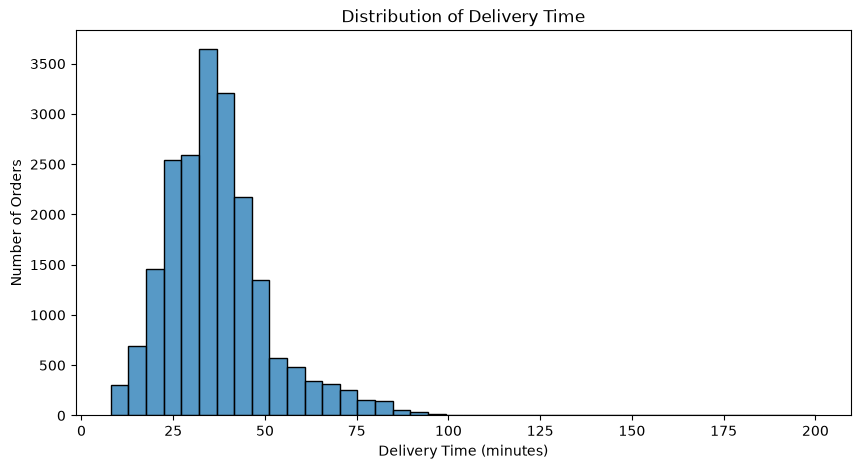

Orders over 60 minutes: 1327
Orders over 100 minutes: 7


In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(abt['DeliveryTimeMinutes'].dropna(), bins=40)
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Orders')
plt.show()

print("Orders over 60 minutes:", (abt['DeliveryTimeMinutes'] > 60).sum())
print("Orders over 100 minutes:", (abt['DeliveryTimeMinutes'] > 100).sum())

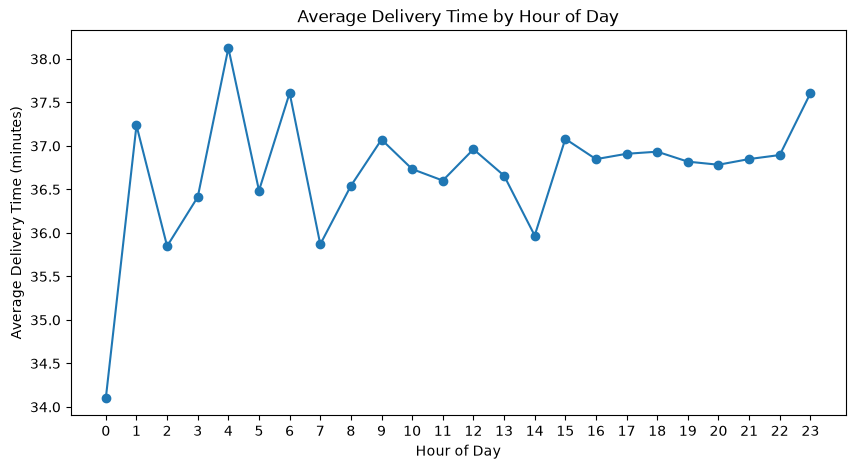

OrderHour
0     34.1
1     37.2
2     35.8
3     36.4
4     38.1
5     36.5
6     37.6
7     35.9
8     36.5
9     37.1
10    36.7
11    36.6
12    37.0
13    36.7
14    36.0
15    37.1
16    36.8
17    36.9
18    36.9
19    36.8
20    36.8
21    36.8
22    36.9
23    37.6
Name: DeliveryTimeMinutes, dtype: float64


In [14]:
hour_time = abt.groupby('OrderHour')['DeliveryTimeMinutes'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hour_time.index, hour_time.values, marker='o')
plt.title('Average Delivery Time by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(range(0, 24))
plt.show()

print(hour_time.round(1))

count    12781.000000
mean        33.931503
std         65.572781
min          0.000000
25%          1.050000
50%          6.800000
75%         32.400000
max        871.900000
Name: Rainfall, dtype: float64

RainStatus
Rain       10479
No Rain     9996
Name: count, dtype: int64


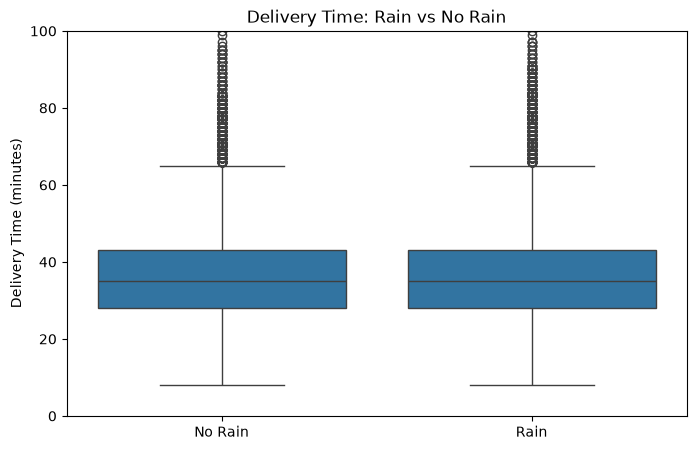

RainStatus
No Rain    36.7
Rain       36.8
Name: DeliveryTimeMinutes, dtype: float64


In [15]:
print(abt['Rainfall'].describe())
print()

abt['RainStatus'] = abt['Rainfall'].apply(lambda x: 'Rain' if x > 0 else 'No Rain')
print(abt['RainStatus'].value_counts())

plt.figure(figsize=(8, 5))
sns.boxplot(data=abt, x='RainStatus', y='DeliveryTimeMinutes')
plt.title('Delivery Time: Rain vs No Rain')
plt.xlabel('')
plt.ylabel('Delivery Time (minutes)')
plt.ylim(0, 100)
plt.show()

print(abt.groupby('RainStatus')['DeliveryTimeMinutes'].mean().round(1))

Rainfall       7694
Temperature    7640
Humidity       7572
dtype: int64

RainStatus
Rain       10479
Unknown     7694
No Rain     2302
Name: count, dtype: int64


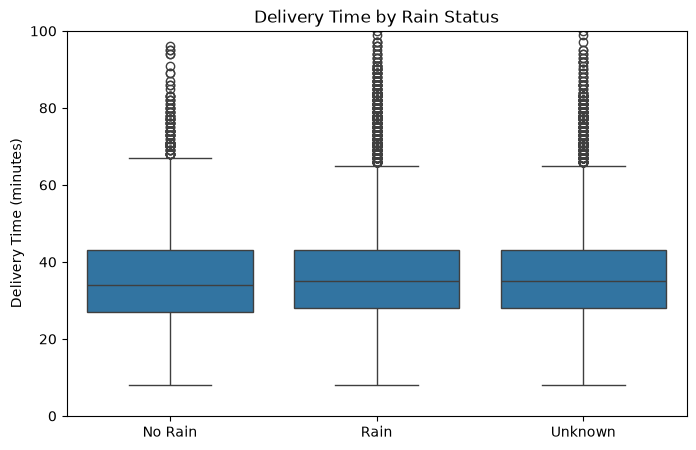

RainStatus
No Rain    36.4
Rain       36.8
Unknown    36.8
Name: DeliveryTimeMinutes, dtype: float64


In [16]:
print(abt[['Rainfall', 'Temperature', 'Humidity']].isna().sum())
print()

abt['RainStatus'] = np.where(abt['Rainfall'].isna(), 'Unknown',
                    np.where(abt['Rainfall'] > 0, 'Rain', 'No Rain'))
print(abt['RainStatus'].value_counts())

plt.figure(figsize=(8, 5))
sns.boxplot(data=abt, x='RainStatus', y='DeliveryTimeMinutes',
            order=['No Rain', 'Rain', 'Unknown'])
plt.title('Delivery Time by Rain Status')
plt.xlabel('')
plt.ylabel('Delivery Time (minutes)')
plt.ylim(0, 100)
plt.show()

print(abt.groupby('RainStatus')['DeliveryTimeMinutes'].mean().round(1))

Overall cancellation rate: 22.3 %

PaymentMethod
Debit Card          3533
Net Banking         3459
Cash on Delivery    3443
Credit Card         3349
Wallet              3348
UPI                 3343
Name: count, dtype: int64


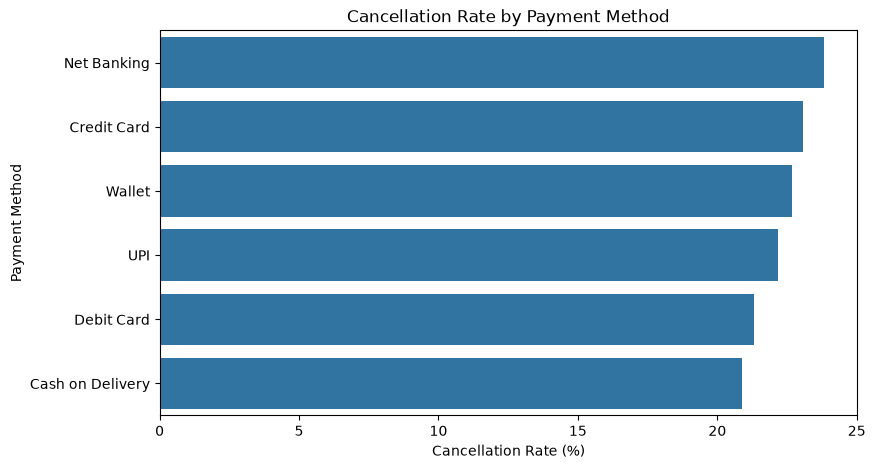

PaymentMethod
Net Banking         23.8
Credit Card         23.1
Wallet              22.7
UPI                 22.2
Debit Card          21.3
Cash on Delivery    20.9
Name: IsCancelled, dtype: float64


In [17]:
abt['IsCancelled'] = (abt['OrderStatus'] == 'Cancelled').astype(int)

print("Overall cancellation rate:", round(abt['IsCancelled'].mean() * 100, 1), "%")
print()
print(abt['PaymentMethod'].value_counts())

cancel_pay = abt.groupby('PaymentMethod')['IsCancelled'].mean() * 100
cancel_pay = cancel_pay.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=cancel_pay.values, y=cancel_pay.index)
plt.title('Cancellation Rate by Payment Method')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Payment Method')
plt.show()

print(cancel_pay.round(1))

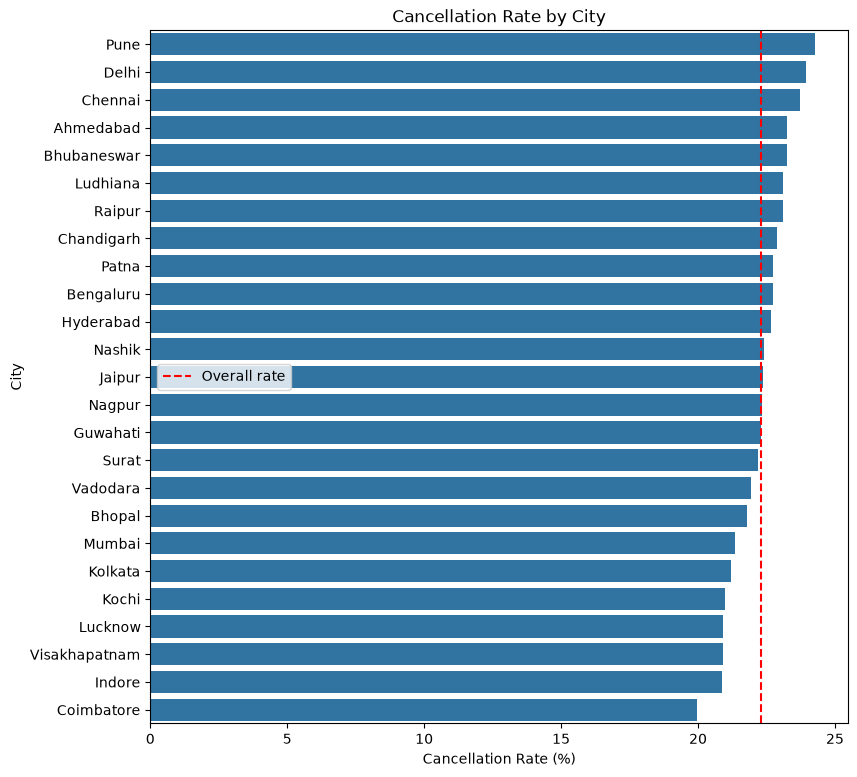

RestaurantCity
Pune       24.3
Delhi      24.0
Chennai    23.7
Name: IsCancelled, dtype: float64
RestaurantCity
Visakhapatnam    20.9
Indore           20.9
Coimbatore       20.0
Name: IsCancelled, dtype: float64


In [18]:
cancel_city = abt.groupby('RestaurantCity')['IsCancelled'].mean() * 100
cancel_city = cancel_city.sort_values(ascending=False)

plt.figure(figsize=(9, 9))
sns.barplot(x=cancel_city.values, y=cancel_city.index)
plt.axvline(abt['IsCancelled'].mean() * 100, color='red', linestyle='--', label='Overall rate')
plt.title('Cancellation Rate by City')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('City')
plt.legend()
plt.show()

print(cancel_city.head(3).round(1))
print(cancel_city.tail(3).round(1))

Membership
Basic         12071
Zomato Pro     4256
Gold           3953
Name: count, dtype: int64

            Orders  CancelRate  AvgOrderValue
Membership                                   
Basic        12071        22.1          392.3
Gold          3953        22.9          391.4
Zomato Pro    4256        22.4          390.2


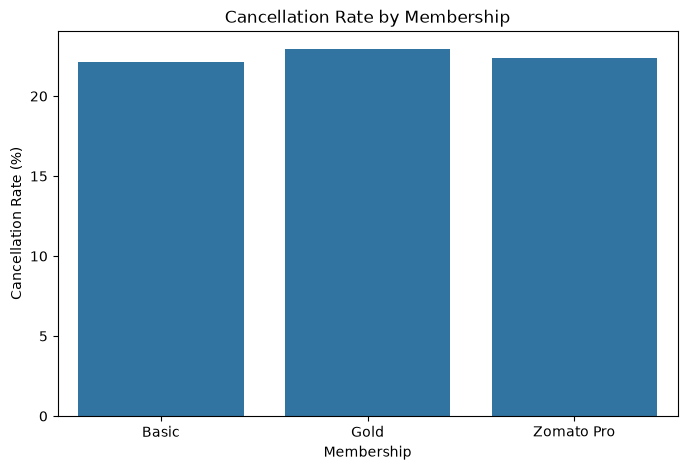

In [19]:
print(abt['Membership'].value_counts())
print()

member_stats = abt.groupby('Membership').agg(
    Orders=('OrderID', 'count'),
    CancelRate=('IsCancelled', 'mean'),
    AvgOrderValue=('FinalAmount', 'mean')
)
member_stats['CancelRate'] = member_stats['CancelRate'] * 100
print(member_stats.round(1))

plt.figure(figsize=(8, 5))
sns.barplot(x=member_stats.index, y=member_stats['CancelRate'])
plt.title('Cancellation Rate by Membership')
plt.xlabel('Membership')
plt.ylabel('Cancellation Rate (%)')
plt.show()

count    20167.000000
mean        30.607874
std          8.505300
min         16.000000
25%         24.000000
50%         30.000000
75%         36.000000
max         66.000000
Name: CustomerAge, dtype: float64

AgeGroup
Under 25    5825
26-35       8650
36-45       4798
46-55        861
Over 55       33
Name: count, dtype: int64

          Orders  CancelRate  AvgOrderValue
AgeGroup                                   
Under 25    5825        23.2          392.1
26-35       8650        21.9          391.5
36-45       4798        22.0          393.0
46-55        861        22.2          386.5
Over 55       33        21.2          375.3


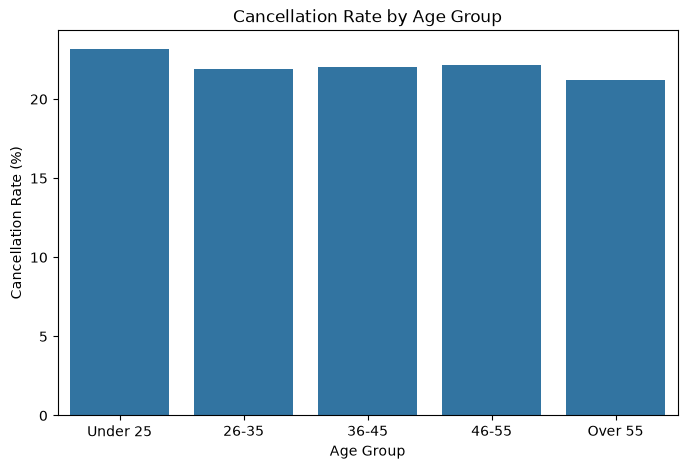

In [20]:
print(abt['CustomerAge'].describe())
print()

abt['AgeGroup'] = pd.cut(abt['CustomerAge'],
                         bins=[0, 25, 35, 45, 55, 120],
                         labels=['Under 25', '26-35', '36-45', '46-55', 'Over 55'])

print(abt['AgeGroup'].value_counts().sort_index())
print()

age_stats = abt.groupby('AgeGroup', observed=True).agg(
    Orders=('OrderID', 'count'),
    CancelRate=('IsCancelled', 'mean'),
    AvgOrderValue=('FinalAmount', 'mean')
)
age_stats['CancelRate'] = age_stats['CancelRate'] * 100
print(age_stats.round(1))

plt.figure(figsize=(8, 5))
sns.barplot(x=age_stats.index, y=age_stats['CancelRate'])
plt.title('Cancellation Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Cancellation Rate (%)')
plt.show()

CustomerRating    6700
DeliveryRating    6537
FoodRating        6410
dtype: int64

                    CustomerRating  DeliveryRating  FoodRating
OrderStatus                                                   
Cancelled                      NaN             NaN         NaN
Delivered                     3.57            3.47        3.48
Delivered Late                3.60            3.50        3.51
Food Not Delivered            3.61            3.51        3.50


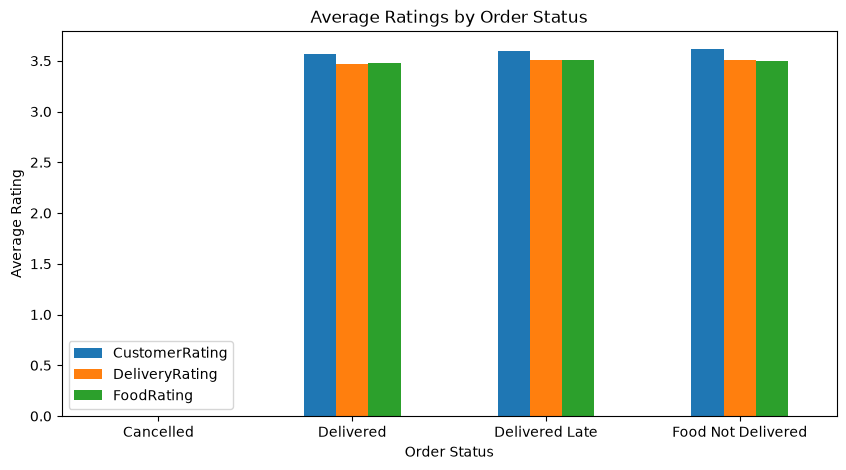

In [21]:
print(abt[['CustomerRating', 'DeliveryRating', 'FoodRating']].isna().sum())
print()

rating_stats = abt.groupby('OrderStatus')[['CustomerRating', 'DeliveryRating', 'FoodRating']].mean()
print(rating_stats.round(2))

rating_stats.plot(kind='bar', figsize=(10, 5))
plt.title('Average Ratings by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)
plt.legend(loc='lower left')
plt.show()

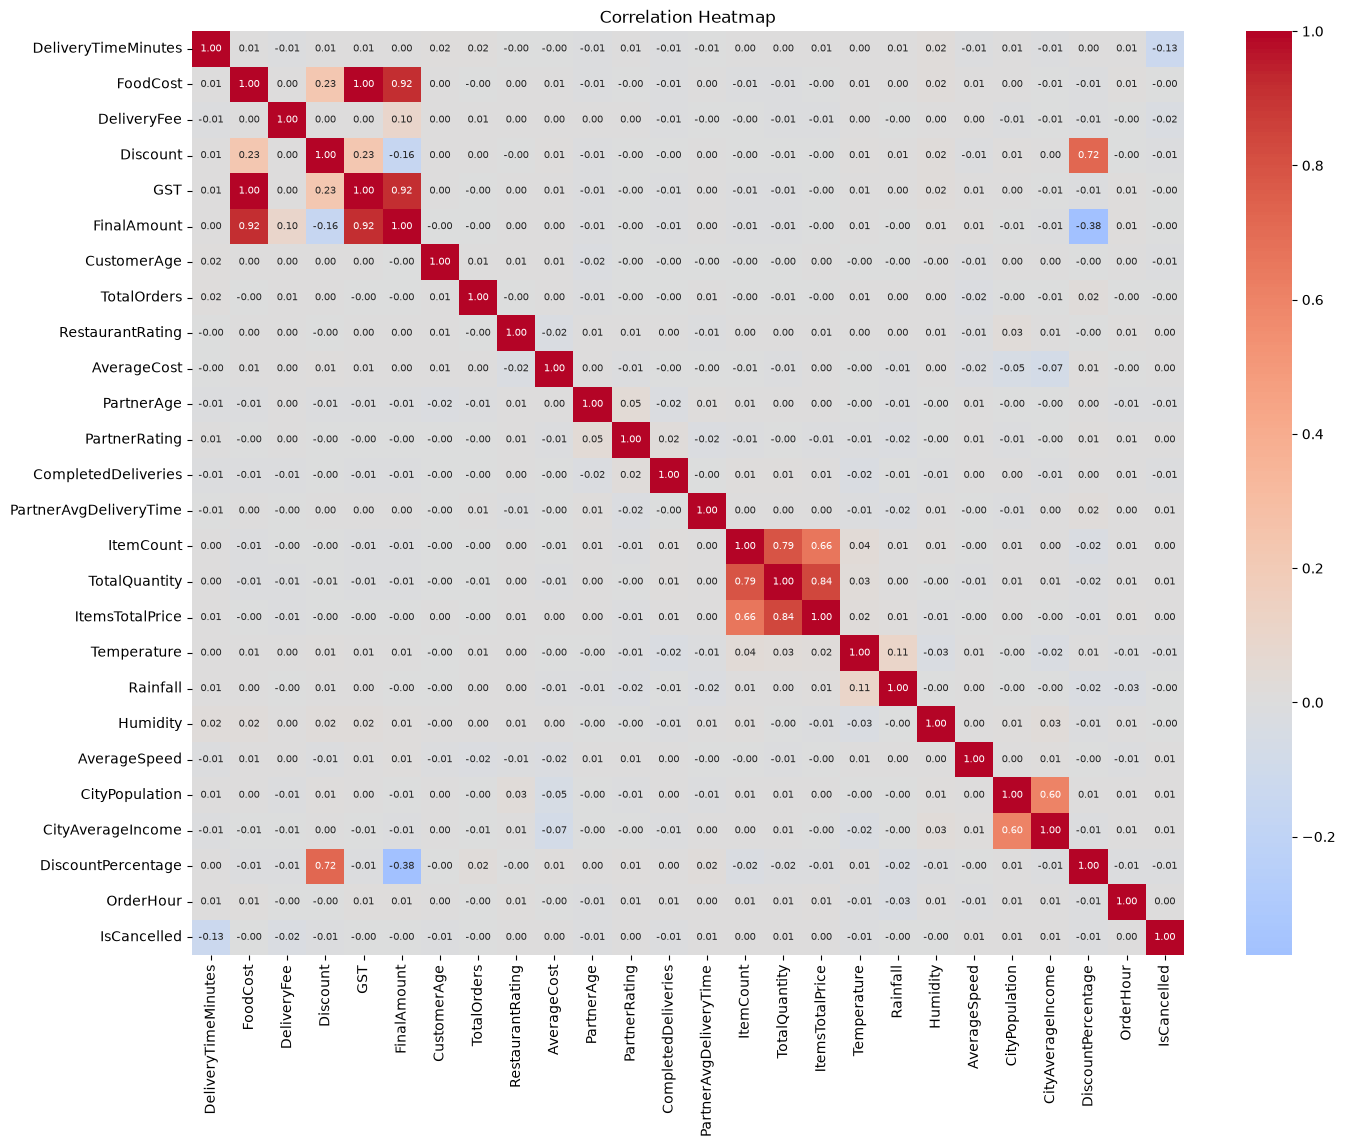

Humidity                  0.017
CustomerAge               0.016
TotalOrders               0.015
Rainfall                  0.010
PartnerRating             0.010
OrderHour                 0.010
Discount                  0.009
ItemsTotalPrice           0.008
GST                       0.008
FoodCost                  0.008
CityPopulation            0.008
DiscountPercentage        0.004
FinalAmount               0.004
TotalQuantity             0.003
ItemCount                 0.002
Temperature               0.001
RestaurantRating         -0.000
AverageCost              -0.000
PartnerAvgDeliveryTime   -0.005
CityAverageIncome        -0.007
DeliveryFee              -0.007
PartnerAge               -0.008
AverageSpeed             -0.014
CompletedDeliveries      -0.014
IsCancelled              -0.129
Name: DeliveryTimeMinutes, dtype: float64

AverageSpeed              0.011
PartnerAvgDeliveryTime    0.010
CityAverageIncome         0.008
CityPopulation            0.007
TotalQuantity             0.0

In [22]:
num_cols = ['DeliveryTimeMinutes', 'FoodCost', 'DeliveryFee', 'Discount', 'GST',
            'FinalAmount', 'CustomerAge', 'TotalOrders', 'RestaurantRating',
            'AverageCost', 'PartnerAge', 'PartnerRating', 'CompletedDeliveries',
            'PartnerAvgDeliveryTime', 'ItemCount', 'TotalQuantity', 'ItemsTotalPrice',
            'Temperature', 'Rainfall', 'Humidity', 'AverageSpeed', 'CityPopulation',
            'CityAverageIncome', 'DiscountPercentage', 'OrderHour', 'IsCancelled']

corr = abt[num_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation Heatmap')
plt.show()

print(corr['DeliveryTimeMinutes'].drop('DeliveryTimeMinutes').sort_values(ascending=False).round(3))
print()
print(corr['IsCancelled'].drop('IsCancelled').sort_values(ascending=False).round(3))

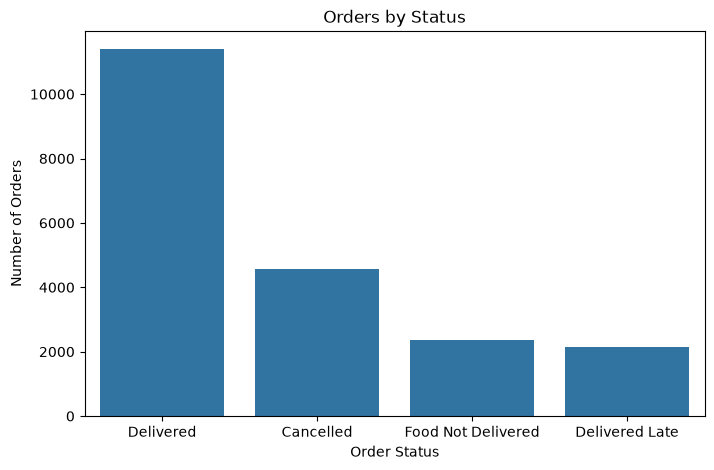

In [23]:
status_counts = abt['OrderStatus'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title('Orders by Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.show()